# 21. Robustness checks: onset definition, futures positioning data and volatility models

Here I check three alternative explanations, on Binance spot BTCUSDT one-minute data over the development period 2023-01 to 2026-04.

- A. Is the 1% onset arbitrary? I redefine the onset as the peak (time of the highest close in the 240 minutes before the breach; an alert counts as pre-onset only if it precedes the peak) and as a changepoint (a two-segment linear fit of log price over the 240 minutes before the breach locates the turn into a downtrend). Under all three definitions I recompute the notebook 16 alerts (four methods) and the notebook 18 per-minute AUC decomposition.
- B. Are the data too thin? I add Binance futures public data (open interest, top-trader and all-account long/short ratios, five-minute taker buy/sell ratio, funding rate) and use only values known in real time: five-minute metrics from 5 minutes after their timestamp, funding from 1 minute after settlement. I compare four models under one procedure: M0 features only (P0, baseline), M0 plus positioning (P1), positioning only (P2) and GBM plus positioning (P3). The windows follow data availability by a rule I fixed before seeing results and recorded in `21_SPEC.json`: protocol A (train 2021, calibrate 2022, evaluate 2023-01 to 2026-04), B (train 2022 H1, calibrate 2022 H2 with 120 alerts, evaluate 2023-01 to 2026-04) or C (train 2023, calibrate 2024 H1 with 120 alerts, evaluate 2024-07 to 2026-04). I keep a feature only if it is present on at least 90% of the minutes in each window. My main run is the first of A and B in which open-interest and funding features are usable; C is a supplementary run if it can use more features (such as the long/short ratios). I retrain the baseline under the same procedure and re-test the notebook 16 and volatility models on the same evaluation window.
- C. Other models. V1 is GJR-GARCH(1,1)-t, which I fit on 2021 five-minute returns and score as the probability of a fall of 4% or more over the next four hours. V2, GARCH plus current drawdown, conditions the same model on the drawdown from the 240-minute trailing high, so by design it rises once a decline begins. V3 is HAR-RV, which forecasts the next four hours of volatility from 1-hour, 4-hour, 1-day and 1-week realized volatility.

I evaluate every new model with the calendar budget of notebook 16 (20 per month, 240 per year, 240-minute spacing), the same endpoint and three nulls (circular shift of at least 7 days, short shift of 4 hours to 1 day, regime-matched).

This analysis is exploratory. I have already examined the development period repeatedly, so I treat these results as robustness checks only. I do not use the holdouts, since positioning data do not exist for 2018–2020. I write the results to `btc_lead_cost_results_77months_spot/onset_positioning_volatility_v1/`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
import joblib, concurrent.futures as cf
from scipy.optimize import minimize
from scipy.stats import t as student_t
from sklearn.ensemble import HistGradientBoostingClassifier

OUT = SPOT_BASE / 'onset_positioning_volatility_v1'; (OUT / 'models').mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
POS_DIR = SPOT_BASE / 'cache' / 'futures_positioning'; POS_DIR.mkdir(parents=True, exist_ok=True)
ZIP_DIR = Path('/content/positioning_zips') if Path('/content').exists() else OUT / 'zips'
DNAME, DCL = '4pct', 0.04
BASE_METHODS = ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich']
N_BOOT = 500; N_NULL = 1000; SEED = 20261104; BLOCK_DAYS = 7
SHORT_BAND = (240, 1440)
METRICS_FROM, METRICS_TO = '2020-01-01', '2026-04-30'
FUNDING_MONTHS = month_list('2020-01', '2026-04')
POS_LAG_MIN = 5; METRICS_STALE_MIN = 30; FUNDING_STALE_MIN = 12 * 60
ZWIN30 = 30 * 1440; ZMIN30 = 15 * 1440
CP_MIN_SEG = 10
BAR = 5; HBARS = LEAD_MAX // BAR
EVAL_LAST = ts(EVAL_END).value - (LEAD_MAX + 5) * NS
POS = ['oi_chg_60', 'oi_chg_240', 'z_oi_chg_1440', 'z_top_pos_ls', 'z_acct_ls', 'z_taker_ls_60', 'funding_bp', 'z_funding']

for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json', M16 / '4_methods_definitions_nulls.csv']:
    if not _p.is_file():
        raise FileNotFoundError(f'Notebook 16 results are required: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')

SPEC = {'title': 'Reviewer checks: alternative onsets, futures positioning data, volatility models (dev 2023-01..2026-04, exploratory)',
        'A_onsets': {'peak': 'argmax close in the 240 min before the breach (catalog peak); pre = alert before the peak',
                     'changepoint': f'two-segment least-squares fit of log close over [breach-240, breach]; break minimising total SSE with both segments >= {CP_MIN_SEG} min, '
                                    'second slope negative and below the first; fallback to the 1% onset if no admissible break',
                     'alerts': 'notebook-16 dev alarms (4%), matching unchanged', 'per_minute': 'notebook-18 L1 decomposition with the in-decline split at each onset'},
        'B_positioning': {'source': 'Binance USD-M futures BTCUSDT daily metrics (5-min open interest, top-trader and account long/short ratios, taker long/short volume ratio) '
                                    'and monthly funding-rate archives; SHA-256 checked when a .CHECKSUM is published',
                          'causality': f'metrics usable {POS_LAG_MIN} min after create_time (stale after {METRICS_STALE_MIN} min); funding usable 1 min after calc_time '
                                       f'(stale after {FUNDING_STALE_MIN} min)',
                          'features': POS, 'z_scores': 'trailing 30 days, min 15 days, shifted one minute',
                          'models': {'P0_VF_refit': 'logit on z_vol, tsr', 'P1_VF_positioning': 'logit on z_vol, tsr + positioning',
                                     'P2_positioning_only': 'logit on positioning', 'P3_GBM_positioning': 'notebook-16 GBM settings on FEATS + positioning'},
                          'protocols': {'A': 'train 2021, calibrate 2022 (240 alerts), evaluate 2023-01..2026-04',
                                        'B': 'train 2022-01..06, calibrate 2022-07..12 (120 alerts), evaluate 2023-01..2026-04',
                                        'C': 'train 2023, calibrate 2024-01..06 (120 alerts), evaluate 2024-07..2026-04'},
                          'run_rule': 'a feature is usable in a protocol if present on >= 90% of valid minutes in each window (>= 95% for training in A). '
                                      'Main run: first of A, B in which the open-interest and funding features are usable, with all usable features. '
                                      'Supplementary run: C if it can use more features. Depends on data availability only. Evaluation alerts 240/yr, 20/month',
                          'asof': 'last finite positive value per field; an empty field never masks an earlier value',
                          'comparison_mask': 'per run: its evaluation window, minutes where its positioning features exist; '
                                             'notebook-16 and volatility models re-tested on a shorter window for reference'},
        'C_volatility': {'V1_GJR_GARCH_t': '5-min log returns, GJR-GARCH(1,1) Student-t fitted by ML on 2021; score = P(4h return <= ln 0.96) from the aggregated '
                                           '48-bar variance forecast (t approximation)',
                         'V2_GARCH_drawdown': 'same variance; score = P(4h return <= ln(0.96 / (1 - current drawdown from the trailing-240-min high)))',
                         'V3_HAR_RV': 'OLS on 2021 of log next-4h realised variance on log 1h, 4h, 1d, 1w realised variance (5-min bars)',
                         'causality': 'minute t uses the last completed 5-min bar', 'calibration': '2022, notebook-5 rule (240 alerts)'},
        'nulls': {'circular': '>= 7 days', 'short': f'+-{SHORT_BAND} minutes', 'regime': '24h-RV decile, +-30 days, >= 240 min away'},
        'draws': N_NULL, 'bootstrap': f'{N_BOOT} x {BLOCK_DAYS}-day blocks', 'seed': SEED, 'notebook16_spec_sha256': FROZEN16['spec_sha256'],
        'holdouts': 'not used'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '21_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'21_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/onset_positioning_volatility_v1 | spec sha256 ff25861e430f5bf6


## 1. Data, events, existing scores and alerts (notebook 16 reproduction check)

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
EVP = VALID & in_period(T, EVAL_START, EVAL_END)
EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
DD240 = F.dd_240.to_numpy(float); CALM = np.isfinite(DD240) & (DD240 < DCL / 4)
_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
N_WEEKS = int(WEEK[EVM].max()) + 1

TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']
E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
E = price_only_catalog(close, volume, px.index, decline=DCL)
for c_ in TCOLS:
    E[c_] = pd.to_datetime(E[c_], utc=True)
E = E.sort_values('breach_utc').reset_index(drop=True)
if len(E) != len(E_ref) or any(not np.array_equal(E[c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS):
    raise RuntimeError('GUARD FAIL: 4% catalog differs from the notebook-2 catalog')
BR = E.breach_utc.astype('int64').to_numpy()
EV = events_between(E, EVAL_START, EVAL_END)
E_POS = {int(e): k for k, e in enumerate(E.event_id)}; EV_IN_E = np.array([E_POS[int(e)] for e in EV.event_id])
eid_pos = {int(e): k for k, e in enumerate(EV.event_id)}

y_l1 = label_from_catalog(T, E); tr21 = train_mask(T, VALID)
Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = tr21 & np.isfinite(Xl).all(axis=1)
cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
m0 = new_logit().fit(Xl[okl], y_l1[okl])
if not (np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9)):
    raise RuntimeError('GUARD FAIL: M0 refit differs from notebook 16')
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']; mp = SPOT_BASE / cfg3['model_file']
if sha256_file(mp) != cfg3['model_sha256']:
    raise RuntimeError('GUARD FAIL: notebook-16 GBM file SHA-256 differs')
g3 = joblib.load(mp)
IDX = np.flatnonzero(EVM); S = {}
s = np.full(len(T), np.nan); okp = EVM & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
S['M2_VPIN'] = np.where(VALID, F.vpin.to_numpy(float), np.nan)
s = np.full(len(T), np.nan); s[IDX] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[IDX])[:, 1]; S['M3_GBM_rich'] = s
S['B0_RV24h_baseline'] = np.where(VALID, RV, np.nan)

ALERTS = {}
for mname in BASE_METHODS:
    a = np.sort(pd.to_datetime(pd.read_csv(M16 / f'alarms_{mname}_{DNAME}.csv').alarm_utc, utc=True).astype('int64').to_numpy())
    if len(a) != FROZEN16['configs'][f'{mname}|{DNAME}']['dev_alerts']:
        raise RuntimeError(f'GUARD FAIL: notebook-16 alarms for {mname} changed')
    ALERTS[mname] = a
print(f'{len(EV)} dev events, evaluation minutes {int(EVM.sum()):,}; catalog, M0 coefficients, GBM file and alarms verified ({time.time() - t_:.0f}s)')


def eval_case(s, y, inn, base, seed, guard=False):
    m = base & np.isfinite(s) & (DEC >= 0)
    code = np.where(y[m] == 1, np.where(inn[m], 2, 1), 0).astype(np.int64)
    P = make_parts(s[m], code, CALM[m], WEEK[m], DEC[m])
    point = stats_from(P, np.ones(N_WEEKS))
    point.update(n_pre=int((code == 1).sum()), n_in=int((code == 2).sum()), n_neg=int((code == 0).sum()))
    if guard:
        from sklearn.metrics import roc_auc_score
        keep = code != 2
        if abs(roc_auc_score((code[keep] > 0).astype(int), s[m][keep]) - point['auc_pre']) > 1e-9:
            raise RuntimeError('GUARD FAIL: block-pair AUC differs from sklearn')
        print('PASS: block-pair AUC equals sklearn')
    rng = np.random.default_rng(seed); boot = {k: np.empty(N_BOOT) for k in STAT_KEYS}
    for i in range(N_BOOT):
        r = stats_from(P, np.bincount(rng.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float))
        for k in STAT_KEYS:
            boot[k][i] = r[k]
    for k in STAT_KEYS:
        lo, hi = np.nanpercentile(boot[k], [2.5, 97.5]) if np.isfinite(boot[k]).any() else (np.nan, np.nan)
        point[f'{k}_lo'] = float(lo); point[f'{k}_hi'] = float(hi)
    return point


def in_decline_mask(onset_all):
    """Positive L1 minutes at or after the onset of the event that makes them positive."""
    pos = np.searchsorted(BR, T + LEAD_MIN * NS, 'left'); ok = pos < len(BR)
    inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= onset_all[pos[ok]]
    return inn & (y_l1 == 1)


# null draws (same constructions as notebooks 16 and 19), for any evaluation window
def make_space(start, end):
    ev = events_between(E, start, end)
    okd = in_period(T, start, end) & np.isfinite(RV)
    tt = T[okd]; dq = np.minimum((pd.Series(RV[okd]).rank(pct=True).to_numpy() * 10).astype(int), 9)
    o = np.lexsort((tt, dq)); ds = dq[o]
    return dict(start=start, end=end, EV=ev, eid_pos={int(e): k for k, e in enumerate(ev.event_id)},
                in_E=np.array([E_POS[int(e)] for e in ev.event_id], dtype=np.int64), t0=ts(start).value, L=(ts(end).value - ts(start).value) // NS,
                TT=tt, DD=dq, PP=tt[o], STARTS=np.searchsorted(ds, np.arange(10), 'left'), ENDS=np.searchsorted(ds, np.arange(10), 'right'))


def draw_circular(a, rng, sp):
    d = int(rng.integers(7 * 1440, sp['L'] - 7 * 1440))
    return np.sort(sp['t0'] + (a - sp['t0'] + d * NS) % (sp['L'] * NS))


def draw_short(a, rng, sp):
    d = int(rng.integers(SHORT_BAND[0], SHORT_BAND[1] + 1)) * (1 if rng.random() < 0.5 else -1)
    return np.sort(sp['t0'] + (a - sp['t0'] + d * NS) % (sp['L'] * NS))


def draw_regime(a, rng, sp, W=30 * 1440 * NS):
    TT_, PP_, STARTS_, ENDS_ = sp['TT'], sp['PP'], sp['STARTS'], sp['ENDS']
    j = np.clip(np.searchsorted(TT_, a, 'right') - 1, 0, len(TT_) - 1); ad = sp['DD'][j]
    lo = np.array([STARTS_[q] + np.searchsorted(PP_[STARTS_[q]:ENDS_[q]], ti - W, 'left') for ti, q in zip(a, ad)])
    hi = np.array([STARTS_[q] + np.searchsorted(PP_[STARTS_[q]:ENDS_[q]], ti + W, 'right') for ti, q in zip(a, ad)])
    c = PP_[lo + (rng.random(len(a)) * (hi - lo)).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
    for _ in range(20):
        if not bad.any():
            break
        c[bad] = PP_[lo[bad] + (rng.random(int(bad.sum())) * (hi[bad] - lo[bad])).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
    return np.sort(c)


NULLS = [('circular >=7d', draw_circular), ('short 4h-1d', draw_short), ('regime-matched', draw_regime)]


def counts_multi(a, ON, sp):
    m = match_events(sp['EV'], np.sort(np.asarray(a, np.int64)))
    if not len(m):
        return {k: (0, 0) for k in ON}, 0
    k = np.array([sp['eid_pos'][int(e)] for e in m.event_id]); al = m.alarm_utc.astype('int64').to_numpy()
    out = {}
    for name, on in ON.items():
        pre = int((al < on[k]).sum()); out[name] = (pre, len(m) - pre)
    return out, len(m)


def null_table(label, a, ON, seed, sp):
    """ON: onset arrays aligned with sp['EV']. a: alerts inside the window."""
    obs, caught = counts_multi(a, ON, sp); rows = []
    for ni, (nname, drawer) in enumerate(NULLS):
        rng = np.random.default_rng(seed + ni)
        pre_d = {x: np.empty(N_NULL) for x in ON}; post_d = {x: np.empty(N_NULL) for x in ON}
        for i in range(N_NULL):
            c, _ = counts_multi(drawer(a, rng, sp), ON, sp)
            for x in ON:
                pre_d[x][i], post_d[x][i] = c[x]
        for x in ON:
            po, qo = obs[x]
            rows.append(dict(method=label, window=f"{sp['start']}..{sp['end']}", onset=x, null=nname, alerts=len(a), events=len(sp['EV']), caught=caught,
                             pre=po, post=qo, pre_null_mean=float(pre_d[x].mean()), post_null_mean=float(post_d[x].mean()),
                             p_pre=(1 + int((pre_d[x] >= po).sum())) / (N_NULL + 1), p_post=(1 + int((post_d[x] >= qo).sum())) / (N_NULL + 1),
                             pre_excess_per_100_alerts=100 * (po - float(pre_d[x].mean())) / max(len(a), 1),
                             post_excess_per_100_alerts=100 * (qo - float(post_d[x].mean())) / max(len(a), 1)))
    return rows, obs, caught


def in_window(a, sp):
    a = np.asarray(a, np.int64); return a[(a >= sp['t0']) & (a < ts(sp['end']).value)]


SP_DEV = make_space(EVAL_START, EVAL_END)
assert SP_DEV['EV'].event_id.tolist() == EV.event_id.tolist()

83 dev events, evaluation minutes 1,750,612; catalog, M0 coefficients, GBM file and alarms verified (71s)


## A. Alternative onset definitions: 1%, peak, changepoint

In [3]:
def changepoint_onsets(Ev):
    """Two-segment least-squares break in log close over [breach-240, breach]."""
    br = ((Ev.breach_utc.astype('int64').to_numpy() - T[0]) // NS).astype(np.int64)
    o1 = Ev.onset_1pct_utc.astype('int64').to_numpy(); out = np.empty(len(Ev), np.int64); fb = 0
    for k, q in enumerate(br):
        y = np.log(pd.Series(close[q - LEAD_MAX:q + 1]).ffill().bfill().to_numpy()); n = len(y); x = np.arange(n, dtype=float)
        P1, Px, Pxx, Py, Pxy, Pyy = (np.r_[0.0, np.cumsum(v)] for v in (np.ones(n), x, x * x, y, x * y, y * y))
        s = np.arange(CP_MIN_SEG, n - CP_MIN_SEG + 1)

        def seg(a, b):
            m_ = P1[b] - P1[a]; sx = Px[b] - Px[a]; sxx = Pxx[b] - Pxx[a]; sy = Py[b] - Py[a]; sxy = Pxy[b] - Pxy[a]; syy = Pyy[b] - Pyy[a]
            den = m_ * sxx - sx * sx; slope = (m_ * sxy - sx * sy) / den
            sse = syy - sy * sy / m_ - (m_ * sxy - sx * sy) ** 2 / (m_ * den)
            return sse, slope
        e1, b1 = seg(np.zeros_like(s), s); e2, b2 = seg(s, np.full_like(s, n))
        ok = (b2 < 0) & (b2 < b1)
        if ok.any():
            j = s[ok][np.argmin((e1 + e2)[ok])]; out[k] = T[q - LEAD_MAX + j]
        else:
            out[k] = o1[k]; fb += 1
    return out, fb


CP_ALL, CP_FALLBACK = changepoint_onsets(E)
ON_ALL = {'1pct': E.onset_1pct_utc.astype('int64').to_numpy(), 'peak': E.peak_utc.astype('int64').to_numpy(), 'changepoint': CP_ALL}
ON_EV = {k: v[EV_IN_E] for k, v in ON_ALL.items()}
br_ev = EV.breach_utc.astype('int64').to_numpy()
ONSET_DESC = pd.DataFrame([dict(onset=k, events=len(EV), median_min_before_breach=float(np.median((br_ev - v) / NS)),
                                median_min_vs_1pct=float(np.median((v - ON_EV['1pct']) / NS)),
                                pre_eligible=int(((br_ev - v) / NS < LEAD_MAX).sum()), post_eligible=int(((br_ev - v) / NS >= LEAD_MIN).sum()))
                           for k, v in ON_EV.items()])
ONSET_DESC['share_before_1pct_onset'] = [float((v < ON_EV['1pct']).mean()) for v in ON_EV.values()]
ONSET_DESC.to_csv(OUT / '1_onset_definitions.csv', index=False); display(ONSET_DESC.round(3))
pd.DataFrame({'event_id': EV.event_id, 'breach_utc': EV.breach_utc,
              **{f'{k}_utc': pd.to_datetime(v, utc=True) for k, v in ON_EV.items()},
              **{f'{k}_min_before_breach': (br_ev - v) / NS for k, v in ON_EV.items()}}).to_csv(OUT / '1_onset_by_event.csv', index=False)
print(f'change-point fallback to the 1% onset: {CP_FALLBACK} of {len(E)} catalog events')

R16 = pd.read_csv(M16 / '4_methods_definitions_nulls.csv')
rows = []; t_ = time.time()
for mi, mname in enumerate(BASE_METHODS):
    r, obs, caught = null_table(mname, ALERTS[mname], ON_EV, SEED + 100 * mi, SP_DEV)
    r16 = R16[(R16.method == mname) & (R16.definition == DNAME)].iloc[0]
    if (obs['1pct'][0], obs['1pct'][1], caught) != (int(r16.pre), int(r16.post), int(r16.caught)):
        raise RuntimeError(f'GUARD FAIL: {mname} counts at the 1% onset differ from notebook 16')
    rows += r; print(f'{mname}: onset nulls done ({time.time() - t_:.0f}s)', flush=True)
OA = pd.DataFrame(rows); OA.to_csv(OUT / '1_onset_alerts.csv', index=False)
display(OA.pivot_table(index=['method', 'onset'], columns='null', values=['pre_excess_per_100_alerts', 'post_excess_per_100_alerts']).round(2))
display(OA.pivot_table(index=['method', 'onset'], columns='null', values=['p_pre', 'p_post']).round(4))

prow = []; ci = 0
for oname, on in ON_ALL.items():
    inn = in_decline_mask(on)
    for sname in BASE_METHODS + ['B0_RV24h_baseline']:
        r = eval_case(S[sname], y_l1, inn, EVM, SEED + 5000 + ci, guard=(ci == 0)); ci += 1
        prow.append(dict(onset=oname, score=sname, **r))
OP = pd.DataFrame(prow); OP.to_csv(OUT / '1_onset_per_minute.csv', index=False)
display(OP.pivot(index='score', columns='onset', values='in_share_of_excess').round(3))
display(OP.pivot(index='score', columns='onset', values='auc_pre_within_regime').round(3))

,onset,events,median_min_before_breach,median_min_vs_1pct,pre_eligible,post_eligible,share_before_1pct_onset
0,1pct,83,119.0,0.0,83,75,0.000
1,peak,83,178.0,-35.0,81,79,1.000
2,changepoint,83,79.0,5.0,83,70,0.386


change-point fallback to the 1% onset: 0 of 269 catalog events
M0_VF_logit: onset nulls done (20s)
M1_vol_threshold: onset nulls done (39s)
M2_VPIN: onset nulls done (57s)
M3_GBM_rich: onset nulls done (76s)


post_excess_per_100_alerts                 \
null                                      circular >=7d regime-matched   
method           onset                                                   
M0_VF_logit      1pct                              1.70           1.64   
                 changepoint                       1.71           1.65   
                 peak                              2.60           2.55   
M1_vol_threshold 1pct                              1.84           1.73   
                 changepoint                       1.58           1.50   
                 peak                              2.50           2.37   
M2_VPIN          1pct                              0.09           0.06   
                 changepoint                       0.09           0.07   
                 peak                              0.23           0.22   
M3_GBM_rich      1pct                              2.06           1.86   
                 changepoint                       1.40           1.25   
                 peak                              2.36           2.10   

                                         pre_excess_per_100_alerts  \
null                         short 4h-1d             circular >=7d   
method           onset                                               
M0_VF_logit      1pct               1.26                      2.17   
                 changepoint        1.36                      2.16   
                 peak               2.00                      1.27   
M1_vol_threshold 1pct               1.39                      1.93   
                 changepoint        1.24                      2.19   
                 peak               1.86                      1.27   
M2_VPIN          1pct              -0.01                      0.53   
                 changepoint        0.01                      0.53   
                 peak               0.05                      0.39   
M3_GBM_rich      1pct               1.61                      0.33   
                 changepoint        1.01                      0.99   
                 peak               1.64                      0.03   

                                                         
null                         regime-matched short 4h-1d  
method           onset                                   
M0_VF_logit      1pct                  2.03        1.69  
                 changepoint           2.02        1.59  
                 peak                  1.12        0.95  
M1_vol_threshold 1pct                  1.77        1.43  
                 changepoint           2.01        1.58  
                 peak                  1.13        0.96  
M2_VPIN          1pct                  0.46        0.28  
                 changepoint           0.45        0.25  
                 peak                  0.30        0.21  
M3_GBM_rich      1pct                  0.09       -0.33  
                 changepoint           0.70        0.27  
                 peak                 -0.15       -0.36

p_post                             \
null                         circular >=7d regime-matched short 4h-1d   
method           onset                                                  
M0_VF_logit      1pct               0.0010         0.0010      0.0010   
                 changepoint        0.0010         0.0010      0.0010   
                 peak               0.0010         0.0010      0.0010   
M1_vol_threshold 1pct               0.0010         0.0010      0.0010   
                 changepoint        0.0010         0.0010      0.0010   
                 peak               0.0010         0.0010      0.0010   
M2_VPIN          1pct               0.4236         0.4805      0.6304   
                 changepoint        0.4056         0.4426      0.5415   
                 peak               0.2867         0.2577      0.4775   
M3_GBM_rich      1pct               0.0010         0.0010      0.0010   
                 changepoint        0.0010         0.0010      0.0030   
                 peak               0.0010         0.0010      0.0080   

                                     p_pre                             
null                         circular >=7d regime-matched short 4h-1d  
method           onset                                                 
M0_VF_logit      1pct               0.0010         0.0010      0.0010  
                 changepoint        0.0010         0.0010      0.0010  
                 peak               0.0020         0.0010      0.0010  
M1_vol_threshold 1pct               0.0010         0.0010      0.0010  
                 changepoint        0.0010         0.0010      0.0010  
                 peak               0.0010         0.0010      0.0010  
M2_VPIN          1pct               0.0619         0.0809      0.1479  
                 changepoint        0.0769         0.0789      0.1648  
                 peak               0.0849         0.1469      0.1329  
M3_GBM_rich      1pct               0.1838         0.4346      0.6993  
                 changepoint        0.0120         0.0330      0.3187  
                 peak               0.5235         0.8132      0.9101

PASS: block-pair AUC equals sklearn


onset,1pct,changepoint,peak
score,,,
B0_RV24h_baseline,0.505,0.376,0.619
M0_VF_logit,0.615,0.463,0.737
M1_vol_threshold,0.613,0.462,0.734
M2_VPIN,NaN,NaN,NaN
M3_GBM_rich,0.646,0.473,0.779


onset,1pct,changepoint,peak
score,,,
B0_RV24h_baseline,0.511,0.511,0.510
M0_VF_logit,0.592,0.617,0.587
M1_vol_threshold,0.594,0.618,0.589
M2_VPIN,0.464,0.458,0.462
M3_GBM_rich,0.547,0.587,0.520


## B. Futures positioning data: open interest, long/short ratios, funding rate

In [4]:
def fetch_verified(url, dest):
    dest = Path(dest)
    chk = _fetch(url + '.CHECKSUM')
    expected = chk.decode().split()[0].strip().lower() if chk is not None else None
    if expected and dest.is_file() and sha256_file(dest) == expected:
        return dict(url=url, sha256=expected, status='cached')
    data = _fetch(url)
    if data is None:
        return dict(url=url, sha256=None, status='not_listed')
    h = hashlib.sha256(data).hexdigest()
    if expected and h != expected:
        raise RuntimeError(f'SHA-256 mismatch: {url}')
    dest.parent.mkdir(parents=True, exist_ok=True); part = dest.parent / (dest.name + '.part'); part.write_bytes(data); part.replace(dest)
    return dict(url=url, sha256=h, status='downloaded' if expected else 'downloaded_no_checksum')


METRIC_COLS = ['create_time', 'symbol', 'sum_open_interest', 'sum_open_interest_value', 'count_toptrader_long_short_ratio',
               'sum_toptrader_long_short_ratio', 'count_long_short_ratio', 'sum_taker_long_short_vol_ratio']
FUNDING_COLS = ['calc_time', 'funding_interval_hours', 'last_funding_rate']


def read_zip_csv(path, default_cols):
    """Header row if present; otherwise the documented column order."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        with zf.open(members[0]) as fd:
            d = pd.read_csv(fd, header=None, dtype=str)
    first = str(d.iloc[0, 0]).strip().lower()
    if not first[:1].isdigit():
        d.columns = [str(c).strip().lower() for c in d.iloc[0]]; d = d.iloc[1:].reset_index(drop=True)
    else:
        if d.shape[1] != len(default_cols):
            raise ValueError(f'{path}: {d.shape[1]} columns without a header; expected {default_cols}')
        d.columns = default_cols
    return d


def to_utc(col):
    v = pd.to_numeric(col, errors='coerce')
    if v.notna().mean() > 0.9:
        mag = float(v.abs().median()); unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
        return pd.to_datetime(v, unit=unit, utc=True)
    return pd.to_datetime(col, utc=True)


METRICS_PQ = POS_DIR / 'BTCUSDT_um_metrics_5m.parquet'; FUNDING_PQ = POS_DIR / 'BTCUSDT_um_funding.parquet'; MAN_CSV = POS_DIR / 'positioning_manifest.csv'
_cache_ok = METRICS_PQ.is_file() and FUNDING_PQ.is_file() and MAN_CSV.is_file()
if _cache_ok:
    MAN = pd.read_csv(MAN_CSV); _mp = MAN[MAN.kind == 'metrics'].period.astype(str)
    _cache_ok = len(_mp) > 0 and _mp.min() <= METRICS_FROM and _mp.max() >= METRICS_TO      # cache must span the requested days
if _cache_ok:
    MET = pd.read_parquet(METRICS_PQ); FUN = pd.read_parquet(FUNDING_PQ)
    print('reusing cached positioning data:', METRICS_PQ.name, len(MET), 'rows;', FUNDING_PQ.name, len(FUN), 'rows')
else:
    t_ = time.time(); days = pd.date_range(METRICS_FROM, METRICS_TO, freq='D').strftime('%Y-%m-%d')
    jobs = [(f'{BINANCE}futures/um/daily/metrics/BTCUSDT/BTCUSDT-metrics-{d}.zip', ZIP_DIR / 'metrics' / f'BTCUSDT-metrics-{d}.zip', 'metrics', d) for d in days]
    jobs += [(f'{BINANCE}futures/um/monthly/fundingRate/BTCUSDT/BTCUSDT-fundingRate-{m}.zip', ZIP_DIR / 'funding' / f'BTCUSDT-fundingRate-{m}.zip', 'funding', m)
             for m in FUNDING_MONTHS]
    with cf.ThreadPoolExecutor(max_workers=16) as ex:
        res = list(ex.map(lambda j: dict(kind=j[2], period=j[3], file=j[1].name, **fetch_verified(j[0], j[1])), jobs))
    MAN = pd.DataFrame(res); print(MAN.groupby(['kind', 'status']).size().to_string(), f'({time.time() - t_:.0f}s)')
    got = MAN[MAN.status != 'not_listed']
    met = []
    for r in got[got.kind == 'metrics'].itertuples():
        met.append(read_zip_csv(ZIP_DIR / 'metrics' / r.file, METRIC_COLS))
    MET = pd.concat(met, ignore_index=True)
    MET['time'] = to_utc(MET['create_time']); MET = MET.drop(columns=[c for c in ['create_time', 'symbol'] if c in MET.columns])
    MET = MET.drop_duplicates('time', keep='last').sort_values('time').set_index('time').apply(pd.to_numeric, errors='coerce')
    fun = []
    for r in got[got.kind == 'funding'].itertuples():
        d = read_zip_csv(ZIP_DIR / 'funding' / r.file, FUNDING_COLS)
        tc = [c for c in d.columns if 'time' in c][0]; rc = [c for c in d.columns if 'rate' in c][0]
        fun.append(pd.DataFrame({'time': to_utc(d[tc]), 'funding_rate': pd.to_numeric(d[rc], errors='coerce')}))
    FUN = pd.concat(fun).drop_duplicates('time', keep='last').sort_values('time').set_index('time')
    MET.to_parquet(METRICS_PQ); FUN.to_parquet(FUNDING_PQ); MAN.to_csv(MAN_CSV, index=False)
print('metrics:', MET.index.min(), '->', MET.index.max(), f'{len(MET):,} rows; columns', list(MET.columns))
print('funding:', FUN.index.min(), '->', FUN.index.max(), f'{len(FUN):,} rows')
for c_ in ['sum_open_interest', 'sum_toptrader_long_short_ratio', 'count_long_short_ratio', 'sum_taker_long_short_vol_ratio']:
    if c_ not in MET.columns:
        raise RuntimeError(f'metrics column missing: {c_} (columns: {list(MET.columns)})')


def asof_minutes(when_ns, values, stale_min):
    j = np.searchsorted(when_ns, T, 'right') - 1; out = np.full(len(T), np.nan); ok = j >= 0
    ok[ok] = (T[ok] - when_ns[j[ok]]) <= stale_min * NS
    out[ok] = values[j[ok]]
    return out


def z30(x):
    s_ = pd.Series(x); r_ = s_.rolling(ZWIN30, min_periods=ZMIN30)
    return ((s_ - r_.mean().shift(1)) / r_.std().shift(1).replace(0, np.nan)).to_numpy()


def logpos(v):
    v = np.asarray(v, float); return np.log(np.where(v > 0, v, np.nan))


met_t = MET.index.asi8 + POS_LAG_MIN * NS


def metric_minutes(col):
    """Last finite positive value known at minute t (an empty field never masks an earlier value), stale after METRICS_STALE_MIN."""
    v = logpos(MET[col].to_numpy()); ok = np.isfinite(v)
    return asof_minutes(met_t[ok], v[ok], METRICS_STALE_MIN)


# raw coverage by month: rows, non-empty and positive share per column (diagnostic, saved)
_mon = MET.index.tz_convert('UTC').strftime('%Y-%m')
RAWCOV = pd.DataFrame({'rows': MET.groupby(_mon).size()})
for c_ in MET.columns:
    RAWCOV[f'{c_}_nonempty'] = MET[c_].notna().groupby(_mon).mean(); RAWCOV[f'{c_}_positive'] = (MET[c_] > 0).groupby(_mon).mean()
RAWCOV.to_csv(OUT / '2_positioning_raw_coverage_by_month.csv')

oi = metric_minutes('sum_open_interest')
PF = pd.DataFrame(index=px.index)
PF['oi_chg_60'] = oi - pd.Series(oi).shift(60).to_numpy()
PF['oi_chg_240'] = oi - pd.Series(oi).shift(240).to_numpy()
PF['z_oi_chg_1440'] = z30(oi - pd.Series(oi).shift(1440).to_numpy())
PF['z_top_pos_ls'] = z30(metric_minutes('sum_toptrader_long_short_ratio'))
PF['z_acct_ls'] = z30(metric_minutes('count_long_short_ratio'))
PF['z_taker_ls_60'] = z30(pd.Series(metric_minutes('sum_taker_long_short_vol_ratio')).rolling(60, min_periods=30).mean().to_numpy())
_fv = FUN.funding_rate.to_numpy(float); _okf = np.isfinite(_fv)
_fd = asof_minutes(FUN.index.asi8[_okf] + NS, _fv[_okf] * 1e4, FUNDING_STALE_MIN)
PF['funding_bp'] = _fd; PF['z_funding'] = z30(_fd)
PF = PF.replace([np.inf, -np.inf], np.nan).astype('float32')

_vm = pd.Series(VALID, index=px.index); _mm = px.index.strftime('%Y-%m')
FEATCOV = pd.DataFrame({f: pd.Series(np.isfinite(PF[f].to_numpy()) & VALID, index=px.index).groupby(_mm).sum() / _vm.groupby(_mm).sum().replace(0, np.nan)
                        for f in POS})
FEATCOV['all_features'] = pd.Series(np.isfinite(PF[POS].to_numpy()).all(axis=1) & VALID, index=px.index).groupby(_mm).sum() / _vm.groupby(_mm).sum().replace(0, np.nan)
FEATCOV = FEATCOV[FEATCOV.index >= METRICS_FROM[:7]]
FEATCOV.to_csv(OUT / '2_positioning_feature_coverage_by_month.csv')
print('raw metrics coverage by month (share of rows with a positive value):')
display(RAWCOV[[c for c in RAWCOV.columns if c.endswith('_positive')] + ['rows']].round(3))
print('feature coverage by month (share of valid minutes):'); display(FEATCOV.round(3))


def fcov(f, a, b):
    m = VALID & in_period(T, a, b)
    return float(np.isfinite(PF[f].to_numpy()[m]).mean()) if m.any() else 0.0


# Protocol rule (fixed before any outcome is computed; it depends only on data availability).
# A feature is usable in a protocol if it exists on >= 90% of valid minutes in each of its windows (>= 95% for the 2021 training year in A).
# Main run: the first protocol that evaluates the whole dev period (A, then B) in which the open-interest and funding features are usable,
#           with every usable feature. Supplementary run: C, if it can use more features than the main run.
PROTOS = [dict(name='A: train 2021, calibrate 2022, evaluate 2023-01..2026-04', train=('2021-01-01', '2022-01-01'), cal=('2022-01-01', '2023-01-01'),
               B_cal=240, eval=(EVAL_START, EVAL_END), train_min=0.95),
          dict(name='B: train 2022-01..06, calibrate 2022-07..12, evaluate 2023-01..2026-04', train=('2022-01-01', '2022-07-01'),
               cal=('2022-07-01', '2023-01-01'), B_cal=120, eval=(EVAL_START, EVAL_END), train_min=0.90),
          dict(name='C: train 2023, calibrate 2024-01..06, evaluate 2024-07..2026-04', train=('2023-01-01', '2024-01-01'),
               cal=('2024-01-01', '2024-07-01'), B_cal=120, eval=('2024-07-01', EVAL_END), train_min=0.90)]
CORE = ['oi_chg_60', 'oi_chg_240', 'z_oi_chg_1440', 'funding_bp', 'z_funding']
pcov = []
for pr in PROTOS:
    for f in POS:
        pcov.append(dict(protocol=pr['name'][:1], feature=f, train=fcov(f, *pr['train']), cal=fcov(f, *pr['cal']), eval=fcov(f, *pr['eval'])))
PCOV = pd.DataFrame(pcov); PCOV.to_csv(OUT / '2_positioning_protocol_coverage.csv', index=False)
display(PCOV.pivot(index='feature', columns='protocol', values=['train', 'cal', 'eval']).round(3))


def usable(pr):
    q = PCOV[PCOV.protocol == pr['name'][:1]].set_index('feature')
    return [f for f in POS if q.loc[f, 'train'] >= pr['train_min'] and q.loc[f, 'cal'] >= 0.90 and q.loc[f, 'eval'] >= 0.90]


RUNS = []
for pr in PROTOS[:2]:
    if set(CORE) <= set(usable(pr)):
        RUNS.append(dict(pr, tag=pr['name'][0], role='main', feats=usable(pr))); break
_uc = usable(PROTOS[2])
if set(CORE) <= set(_uc) and (not RUNS or len(_uc) > len(RUNS[0]['feats'])):
    RUNS.append(dict(PROTOS[2], tag='C', role='supplementary' if RUNS else 'main', feats=_uc))
if not RUNS:
    raise RuntimeError('positioning data too sparse for every protocol; see 2_positioning_*coverage*.csv')
for R in RUNS:
    R['dropped'] = [f for f in POS if f not in R['feats']]
    R['POS_OK'] = np.isfinite(PF[R['feats']].to_numpy()).all(axis=1); R['WIN'] = in_period(T, *R['eval']); R['SP'] = make_space(*R['eval'])
    print(f"run {R['tag']} ({R['role']}): {R['name']} | features: {R['feats']} | dropped: {R['dropped'] or 'none'} | "
          f"evaluation events: {len(R['SP']['EV'])}")

kind     status    
funding  downloaded      76
metrics  downloaded    2068
         not_listed     244 (74s)
metrics: 2020-09-01 00:00:00+00:00 -> 2026-04-30 23:55:00+00:00 594,950 rows; columns ['sum_open_interest', 'sum_open_interest_value', 'count_toptrader_long_short_ratio', 'sum_toptrader_long_short_ratio', 'count_long_short_ratio', 'sum_taker_long_short_vol_ratio']
funding: 2020-01-01 00:00:00+00:00 -> 2026-04-30 16:00:00+00:00 6,936 rows
raw metrics coverage by month (share of rows with a positive value):


,sum_open_interest_positive,sum_open_interest_value_positive,count_toptrader_long_short_ratio_positive,sum_toptrader_long_short_ratio_positive,count_long_short_ratio_positive,sum_taker_long_short_vol_ratio_positive,rows
time,,,,,,,
2020-09,1.0,1.0,1.0,1.0,1.0,1.0,8636
2020-10,1.0,1.0,1.0,1.0,1.0,1.0,8918
2020-11,1.0,1.0,1.0,1.0,1.0,1.0,8621
2020-12,1.0,1.0,1.0,1.0,1.0,1.0,8928
2021-01,1.0,1.0,1.0,1.0,1.0,1.0,8911
...,...,...,...,...,...,...,...
2025-12,1.0,1.0,1.0,1.0,1.0,1.0,8928
2026-01,1.0,1.0,1.0,1.0,1.0,1.0,8928
2026-02,1.0,1.0,1.0,1.0,1.0,1.0,8064


feature coverage by month (share of valid minutes):


,oi_chg_60,oi_chg_240,z_oi_chg_1440,z_top_pos_ls,z_acct_ls,z_taker_ls_60,funding_bp,z_funding,all_features
open_time,,,,,,,,,
2020-01,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2020-02,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2020-03,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2020-04,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2020-05,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...
2025-12,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2026-01,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2026-02,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


train                cal                 eval            
protocol           A      B    C      A      B      C      A      B    C
feature                                                                 
funding_bp     1.000  1.000  1.0  1.000  1.000  1.000  1.000  1.000  1.0
oi_chg_240     0.996  0.997  1.0  0.998  1.000  0.997  0.999  0.999  1.0
oi_chg_60      0.997  0.998  1.0  0.999  1.000  0.997  1.000  1.000  1.0
z_acct_ls      0.994  0.815  1.0  0.908  1.000  0.998  1.000  1.000  1.0
z_funding      1.000  1.000  1.0  1.000  1.000  1.000  1.000  1.000  1.0
z_oi_chg_1440  0.996  0.996  1.0  0.998  1.000  0.995  0.999  0.999  1.0
z_taker_ls_60  0.994  0.205  1.0  0.606  1.000  0.998  1.000  1.000  1.0
z_top_pos_ls   0.994  0.072  1.0  0.042  0.013  0.998  1.000  1.000  1.0

run A (main): A: train 2021, calibrate 2022, evaluate 2023-01..2026-04 | features: ['oi_chg_60', 'oi_chg_240', 'z_oi_chg_1440', 'z_acct_ls', 'funding_bp', 'z_funding'] | dropped: ['z_top_pos_ls', 'z_taker_ls_60'] | evaluation events: 83
run C (supplementary): C: train 2023, calibrate 2024-01..06, evaluate 2024-07..2026-04 | features: ['oi_chg_60', 'oi_chg_240', 'z_oi_chg_1440', 'z_top_pos_ls', 'z_acct_ls', 'z_taker_ls_60', 'funding_bp', 'z_funding'] | dropped: none | evaluation events: 46


### B-1. Single positioning features: pre-onset ranking ability

I use each feature directly as a score and compute its pre-onset AUC and within-regime AUC; a value below 0.5 means the feature falls before crashes.

In [5]:
INN1 = in_decline_mask(ON_ALL['1pct']); BASEP = EVM          # each feature on its own available dev minutes
urows = []
for k, f in enumerate(POS):
    r = eval_case(PF[f].to_numpy(float), y_l1, INN1, BASEP, SEED + 7000 + k)
    urows.append(dict(feature=f, **{c: r[c] for c in ['n_pre', 'n_in', 'auc_standard', 'auc_pre', 'auc_pre_lo', 'auc_pre_hi', 'auc_in',
                                                     'auc_pre_within_regime', 'auc_pre_within_regime_lo', 'auc_pre_within_regime_hi']}))
UP = pd.DataFrame(urows); UP.to_csv(OUT / '2_positioning_univariate.csv', index=False); display(UP.round(3))

,feature,n_pre,n_in,auc_standard,auc_pre,auc_pre_lo,auc_pre_hi,auc_in,auc_pre_within_regime,auc_pre_within_regime_lo,auc_pre_within_regime_hi
0,oi_chg_60,10268,7245,0.479,0.519,0.466,0.570,0.422,0.518,0.461,0.570
1,oi_chg_240,10268,7245,0.501,0.518,0.449,0.586,0.478,0.524,0.460,0.588
2,z_oi_chg_1440,10268,7245,0.573,0.580,0.512,0.644,0.564,0.599,0.535,0.654
3,z_top_pos_ls,10268,7245,0.544,0.552,0.475,0.625,0.534,0.528,0.467,0.586
4,z_acct_ls,10268,7245,0.558,0.521,0.449,0.587,0.611,0.507,0.441,0.572
5,z_taker_ls_60,10268,7245,0.461,0.517,0.483,0.550,0.383,0.517,0.481,0.552
6,funding_bp,10268,7245,0.570,0.566,0.490,0.646,0.575,0.556,0.491,0.621
7,z_funding,10268,7245,0.532,0.546,0.471,0.619,0.513,0.562,0.501,0.628


### B-2. Models with positioning data: training, calibration and evaluation under one procedure

In [6]:
def period_mask(a, b, embargo=True):
    m = VALID & in_period(T, a, b)
    return m & (T < ts(b).value - (LEAD_MAX + 5) * NS) if embargo else m


XALL = pd.concat([F, PF], axis=1)
FROZEN21 = {'spec_sha256': SPEC_SHA, 'runs': [{k: R[k] for k in ['tag', 'role', 'name', 'train', 'cal', 'eval', 'B_cal', 'feats', 'dropped']} for R in RUNS],
            'models': {}}
P_SCORES = {}; P_ALERTS = {}; P_RUN = {}
for R in RUNS:
    TRN = period_mask(*R['train']) & R['POS_OK']; CALP = period_mask(*R['cal'], embargo=False) & R['POS_OK']
    EVW = EVP & R['WIN']; SCOREP = (CALP | EVW) & R['POS_OK']
    P_MODELS = {'P0_VF_refit': ('logit', ['z_vol', 'tsr']), 'P1_VF_positioning': ('logit', ['z_vol', 'tsr'] + R['feats']),
                'P2_positioning_only': ('logit', R['feats']), 'P3_GBM_positioning': ('gbm', FEATS + R['feats'])}
    for base_name, (kind, cols) in P_MODELS.items():
        name = f"{base_name}[{R['tag']}]"
        X = XALL[cols].to_numpy(np.float32 if kind == 'gbm' else float); okx = np.isfinite(X).all(axis=1) if kind == 'logit' else np.ones(len(T), bool)
        tr = TRN & okx; t0 = time.time()
        if kind == 'logit':
            mdl = new_logit().fit(X[tr], y_l1[tr])
            info = dict(features=cols, coef_standardized=dict(zip(cols, mdl[-1].coef_.ravel().round(6).tolist())), intercept=float(mdl[-1].intercept_[0]))
        else:
            mdl = HistGradientBoostingClassifier(**GBM_PARAMS).fit(X[tr], y_l1[tr])
            mpth = OUT / 'models' / f"{base_name}_{R['tag']}.joblib"; joblib.dump(mdl, mpth)
            info = dict(features=cols, model_file=str(mpth.relative_to(SPOT_BASE)), model_sha256=sha256_file(mpth))
        sc = np.full(len(T), np.nan); ix = np.flatnonzero(SCOREP & okx); sc[ix] = mdl.predict_proba(X[ix])[:, 1]
        okc = CALP & np.isfinite(sc); oke = EVW & np.isfinite(sc)
        th, ncal, _ = calibrate_calendar(T[okc], sc[okc], B_=R['B_cal'])
        a = emit_calendar_fast(T[oke], sc[oke] >= th)
        P_SCORES[name] = sc; P_ALERTS[name] = a; P_RUN[name] = R['tag']
        pd.DataFrame({'alarm_utc': pd.to_datetime(a, utc=True)}).to_csv(OUT / f"alarms_{base_name}_{R['tag']}.csv", index=False)
        FROZEN21['models'][name] = dict(kind=kind, run=R['tag'], train_positives=int(y_l1[tr].sum()), train_minutes=int(tr.sum()), threshold=float(th),
                                        cal_alerts=int(ncal), eval_alerts=len(a), **info)
        print(f'{name:26s} trained on {int(tr.sum()):,} minutes ({int(y_l1[tr].sum()):,} positives); threshold {th:.6g}; '
              f'calibration alerts {ncal}; evaluation alerts {len(a)} ({time.time() - t0:.0f}s)', flush=True)
    print(f"P1[{R['tag']}] standardized coefficients:", FROZEN21['models'][f"P1_VF_positioning[{R['tag']}]"]['coef_standardized'])

P0_VF_refit[A]             trained on 518,929 minutes (18,387 positives); threshold 0.66861; calibration alerts 220; evaluation alerts 800 (3s)
P1_VF_positioning[A]       trained on 518,929 minutes (18,387 positives); threshold 0.601847; calibration alerts 220; evaluation alerts 790 (3s)
P2_positioning_only[A]     trained on 518,929 minutes (18,387 positives); threshold 0.451265; calibration alerts 220; evaluation alerts 787 (3s)
P3_GBM_positioning[A]      trained on 518,929 minutes (18,387 positives); threshold 0.0264555; calibration alerts 220; evaluation alerts 650 (115s)
P1[A] standardized coefficients: {'z_vol': 0.570455, 'tsr': 0.021376, 'oi_chg_60': 0.074063, 'oi_chg_240': 0.177672, 'z_oi_chg_1440': 0.096809, 'z_acct_ls': 0.10255, 'funding_bp': 0.487269, 'z_funding': -0.474589}
P0_VF_refit[C]             trained on 525,156 minutes (3,587 positives); threshold 0.752725; calibration alerts 120; evaluation alerts 440 (1s)
P1_VF_positioning[C]       trained on 525,156 minutes (3,587

## C. Volatility models: GJR-GARCH(1,1)-t, GARCH + current drawdown, HAR-RV

I build log returns (%) from the close of the last minute of each five-minute bar; the score at minute t uses only the last completed five-minute bar.

In [7]:
@njit(cache=False)
def _gjr_path(r, w, a, g, b, h0):
    n = len(r); h = np.empty(n + 1); h[0] = h0
    for i in range(n):
        x = r[i]
        if x == x:
            h[i + 1] = w + (a + (g if x < 0 else 0.0)) * x * x + b * h[i]
        else:
            h[i + 1] = w + (a + 0.5 * g + b) * h[i]
    return h


@njit(cache=False)
def _gjr_nll(r, w, a, g, b, nu, h0, const):
    h = _gjr_path(r, w, a, g, b, h0); s = 0.0
    for i in range(len(r)):
        x = r[i]
        if x == x:
            s += const - 0.5 * math.log(h[i]) - 0.5 * (nu + 1.0) * math.log(1.0 + x * x / (h[i] * (nu - 2.0)))
    return -s


t_ = time.time()
IE = np.flatnonzero((T // NS) % BAR == BAR - 1)
c5 = close[IE]; lc5 = np.log(np.where(np.isfinite(c5) & (c5 > 0), c5, np.nan))
r5 = np.r_[np.nan, np.diff(lc5)] * 100.0
TB = T[IE]
tr_b = (TB >= ts('2021-01-01').value) & (TB < ts('2022-01-01').value - (LEAD_MAX + 5) * NS)
rt = r5[tr_b]; v0 = float(np.nanvar(rt))


def nll(p):
    w, a, g, b, nu = p
    if a + 0.5 * g + b >= 0.9995 or nu <= 2.05 or w <= 0:
        return 1e12
    const = math.lgamma((nu + 1) / 2) - math.lgamma(nu / 2) - 0.5 * math.log(math.pi * (nu - 2))
    return _gjr_nll(rt, w, a, g, b, nu, v0, const)


bounds = [(1e-10, 10 * v0), (0.0, 0.5), (0.0, 0.5), (0.0, 0.9995), (2.1, 60.0)]
fits = [minimize(nll, x0, method='L-BFGS-B', bounds=bounds) for x0 in
        ([v0 * 0.02, 0.05, 0.05, 0.90, 5.0], [v0 * 0.05, 0.10, 0.02, 0.85, 4.0], [v0 * 0.01, 0.03, 0.03, 0.95, 8.0])]
best = min(fits, key=lambda f_: f_.fun)
W_, A_, G_, B_, NU_ = (float(x) for x in best.x); PHI = A_ + 0.5 * G_ + B_
if not (np.isfinite(best.fun) and PHI < 1):
    raise RuntimeError(f'GJR-GARCH fit failed: {best}')
H1 = _gjr_path(np.ascontiguousarray(r5), W_, A_, G_, B_, v0)
JJ = np.searchsorted(IE, np.arange(len(T)), 'right') - 1
h1 = np.full(len(T), np.nan); okj = JJ >= 0; h1[okj] = H1[JJ[okj] + 1]
SBAR = W_ / (1 - PHI)
HAGG = HBARS * SBAR + (h1 - SBAR) * (1 - PHI ** HBARS) / (1 - PHI)
SCALE = math.sqrt(NU_ / (NU_ - 2))
V = {}
V['V1_GJR_GARCH_t'] = np.where(VALID, student_t.cdf(100 * np.log(1 - DCL) / np.sqrt(HAGG) * SCALE, NU_), np.nan)
_thr2 = 100 * np.log((1 - DCL) / np.clip(1 - DD240, 1e-6, None))
V['V2_GARCH_drawdown'] = np.where(VALID & np.isfinite(DD240), student_t.cdf(_thr2 / np.sqrt(HAGG) * SCALE, NU_), np.nan)

q5 = pd.Series(np.where(np.isfinite(r5), r5 ** 2, np.nan))


def lsum(k):
    return np.log(q5.rolling(k, min_periods=k // 2).mean().to_numpy() * k + 1e-10)


XH = np.column_stack([lsum(12), lsum(48), lsum(288), lsum(2016)])
YH = np.log(q5[::-1].rolling(HBARS, min_periods=HBARS // 2).mean()[::-1].shift(-1).to_numpy() * HBARS + 1e-10)
okh = tr_b & np.isfinite(XH).all(axis=1) & np.isfinite(YH)
beta_h = np.linalg.lstsq(np.column_stack([np.ones(okh.sum()), XH[okh]]), YH[okh], rcond=None)[0]
predh = np.column_stack([np.ones(len(XH)), XH]) @ beta_h
v3 = np.full(len(T), np.nan); v3[okj] = predh[JJ[okj]]
V['V3_HAR_RV'] = np.where(VALID, v3, np.nan)
FROZEN21['volatility'] = dict(gjr_garch_t=dict(omega=W_, alpha=A_, gamma=G_, beta=B_, nu=NU_, persistence=PHI, nll=float(best.fun),
                                                train_bars=int(np.isfinite(rt).sum()), units='percent 5-min log returns'),
                              har_rv=dict(coef=dict(zip(['const', 'lrv_1h', 'lrv_4h', 'lrv_1d', 'lrv_1w'], beta_h.round(6).tolist())), train_bars=int(okh.sum())))
print('GJR-GARCH-t:', {k: round(v, 5) for k, v in FROZEN21['volatility']['gjr_garch_t'].items() if isinstance(v, float)})
print('HAR-RV:', FROZEN21['volatility']['har_rv']['coef'])

CAL22 = VALID & in_period(T, '2022-01-01', '2023-01-01'); V_ALERTS = {}
for name, sc in V.items():
    okc = CAL22 & np.isfinite(sc); oke = EVP & np.isfinite(sc)
    th, ncal, _ = calibrate_calendar(T[okc], sc[okc])
    a = emit_calendar_fast(T[oke], sc[oke] >= th); V_ALERTS[name] = a
    pd.DataFrame({'alarm_utc': pd.to_datetime(a, utc=True)}).to_csv(OUT / f'alarms_{name}.csv', index=False)
    FROZEN21['models'][name] = dict(kind='volatility', threshold=float(th), cal_alerts=int(ncal), dev_alerts=len(a))
    print(f'{name:20s} threshold {th:.6g}; 2022 alerts {ncal}; dev alerts {len(a)}')
(OUT / 'MODELS_21.json').write_text(json.dumps(FROZEN21, indent=2, default=float))
print(f'volatility models done ({time.time() - t_:.0f}s); MODELS_21.json sha256', sha256_file(OUT / 'MODELS_21.json')[:16])

GJR-GARCH-t: {'omega': 0.00069, 'alpha': 0.05515, 'gamma': 0.05241, 'beta': 0.91223, 'nu': 5.1287, 'persistence': 0.99359, 'nll': -10511.0455}
HAR-RV: {'const': -1.200986, 'lrv_1h': 0.156896, 'lrv_4h': 0.193134, 'lrv_1d': 0.323302, 'lrv_1w': 0.22337}
V1_GJR_GARCH_t       threshold 0.00868129; 2022 alerts 240; dev alerts 788
V2_GARCH_drawdown    threshold 0.0218149; 2022 alerts 240; dev alerts 792
V3_HAR_RV            threshold -0.37727; 2022 alerts 240; dev alerts 791
volatility models done (20s); MODELS_21.json sha256 378b6b7ace621655


## D. Evaluation of the new models: alert endpoint (three nulls) and per-minute AUC decomposition

In [8]:
rows = []; t_ = time.time(); ON1 = {'1pct': ON_EV['1pct']}
for mi, (name, a) in enumerate(V_ALERTS.items()):
    r, _, _ = null_table(name, a, ON1, SEED + 21000 + 100 * mi, SP_DEV); rows += r
    print(f'{name}: nulls done ({time.time() - t_:.0f}s)', flush=True)
for ri, R in enumerate(RUNS):
    ONR = {'1pct': ON_ALL['1pct'][R['SP']['in_E']]}
    for mi, name in enumerate([n for n in P_ALERTS if P_RUN[n] == R['tag']]):
        r, _, _ = null_table(name, P_ALERTS[name], ONR, SEED + 20000 + 1000 * ri + 100 * mi, R['SP']); rows += r
        print(f'{name}: nulls done ({time.time() - t_:.0f}s)', flush=True)
    if R['eval'] != (EVAL_START, EVAL_END):
        # reference rows on this shorter window: notebook-16 and volatility alerts that fall inside it
        for mi, (name, a) in enumerate({**ALERTS, **V_ALERTS}.items()):
            r, _, _ = null_table(name, in_window(a, R['SP']), ONR, SEED + 30000 + 1000 * ri + 100 * mi, R['SP']); rows += r
        print(f"reference models on window {R['eval']} done ({time.time() - t_:.0f}s)", flush=True)
base_rows = OA[OA.onset == '1pct']
NA = pd.concat([base_rows, pd.DataFrame(rows)], ignore_index=True); NA.to_csv(OUT / '3_new_models_alerts.csv', index=False)
display(NA.pivot_table(index=['window', 'method'], columns='null', values=['pre_excess_per_100_alerts', 'post_excess_per_100_alerts'], sort=False).round(2))
display(NA.pivot_table(index=['window', 'method'], columns='null', values=['p_pre', 'p_post'], sort=False).round(4))

mrows = []; ci = 0
REF_SCORES = {**{k: S[k] for k in BASE_METHODS + ['B0_RV24h_baseline']}, **V}
MASKS = [('all dev minutes', EVM, REF_SCORES)]
for R in RUNS:
    MASKS.append((f"run {R['tag']}: {R['eval'][0]}..{R['eval'][1]}, its positioning features present", EVM & R['POS_OK'] & R['WIN'],
                  {**REF_SCORES, **{n: P_SCORES[n] for n in P_SCORES if P_RUN[n] == R['tag']}}))
for mask_name, base, scores in MASKS:
    for name, sc in scores.items():
        r = eval_case(sc, y_l1, INN1, base, SEED + 40000 + ci); ci += 1
        mrows.append(dict(mask=mask_name, score=name, **r))
MA = pd.DataFrame(mrows); MA.to_csv(OUT / '3_new_models_per_minute.csv', index=False)
display(MA.set_index(['mask', 'score'])[['auc_standard', 'auc_pre', 'auc_in', 'in_share_of_excess', 'auc_pre_within_regime']].round(3))

V1_GJR_GARCH_t: nulls done (21s)
V2_GARCH_drawdown: nulls done (40s)
V3_HAR_RV: nulls done (59s)
P0_VF_refit[A]: nulls done (80s)
P1_VF_positioning[A]: nulls done (104s)
P2_positioning_only[A]: nulls done (126s)
P3_GBM_positioning[A]: nulls done (144s)
P0_VF_refit[C]: nulls done (159s)
P1_VF_positioning[C]: nulls done (174s)
P2_positioning_only[C]: nulls done (187s)
P3_GBM_positioning[C]: nulls done (200s)
reference models on window ('2024-07-01', '2026-05-01') done (292s)


pre_excess_per_100_alerts  \
null                                                      circular >=7d   
window                 method                                             
2023-01-01..2026-05-01 M0_VF_logit                                 2.17   
                       M1_vol_threshold                            1.93   
                       M2_VPIN                                     0.53   
                       M3_GBM_rich                                 0.33   
                       V1_GJR_GARCH_t                              1.35   
                       V2_GARCH_drawdown                           1.70   
                       V3_HAR_RV                                   0.41   
                       P0_VF_refit[A]                              1.93   
                       P1_VF_positioning[A]                        1.44   
                       P2_positioning_only[A]                      0.05   
                       P3_GBM_positioning[A]                       0.34   
2024-07-01..2026-05-01 M0_VF_logit                                 3.33   
                       M1_vol_threshold                            3.11   
                       M2_VPIN                                     0.37   
                       M3_GBM_rich                                 0.68   
                       V1_GJR_GARCH_t                              2.05   
                       V2_GARCH_drawdown                           2.24   
                       V3_HAR_RV                                   0.86   
                       P0_VF_refit[C]                              3.11   
                       P1_VF_positioning[C]                        0.61   
                       P2_positioning_only[C]                     -0.08   
                       P3_GBM_positioning[C]                       0.06   

                                                                          \
null                                          short 4h-1d regime-matched   
window                 method                                              
2023-01-01..2026-05-01 M0_VF_logit                   1.69           2.03   
                       M1_vol_threshold              1.43           1.77   
                       M2_VPIN                       0.28           0.46   
                       M3_GBM_rich                  -0.33           0.09   
                       V1_GJR_GARCH_t                0.77           1.13   
                       V2_GARCH_drawdown             1.13           1.43   
                       V3_HAR_RV                    -0.04           0.24   
                       P0_VF_refit[A]                1.46           1.76   
                       P1_VF_positioning[A]          0.95           1.32   
                       P2_positioning_only[A]       -0.42          -0.06   
                       P3_GBM_positioning[A]        -0.23           0.02   
2024-07-01..2026-05-01 M0_VF_logit                   2.75           3.19   
                       M1_vol_threshold              2.49           2.95   
                       M2_VPIN                      -0.10           0.26   
                       M3_GBM_rich                  -0.04           0.39   
                       V1_GJR_GARCH_t                1.37           1.78   
                       V2_GARCH_drawdown             1.60           1.99   
                       V3_HAR_RV                     0.22           0.65   
                       P0_VF_refit[C]                2.53           2.96   
                       P1_VF_positioning[C]          0.25           0.44   
                       P2_positioning_only[C]       -0.43          -0.21   
                       P3_GBM_positioning[C]        -0.38          -0.09   

                                              post_excess_per_100_alerts  \
null                                                       circular >=7d   
window                 method                                              
2023-01-01..2026-05-01 M0_VF_logit       

p_pre              \
null                                          circular >=7d short 4h-1d   
window                 method                                             
2023-01-01..2026-05-01 M0_VF_logit                   0.0010      0.0010   
                       M1_vol_threshold              0.0010      0.0010   
                       M2_VPIN                       0.0619      0.1479   
                       M3_GBM_rich                   0.1838      0.6993   
                       V1_GJR_GARCH_t                0.0010      0.0609   
                       V2_GARCH_drawdown             0.0010      0.0280   
                       V3_HAR_RV                     0.1059      0.6434   
                       P0_VF_refit[A]                0.0010      0.0010   
                       P1_VF_positioning[A]          0.0010      0.0050   
                       P2_positioning_only[A]        0.4935      0.8761   
                       P3_GBM_positioning[A]         0.1808      0.6993   
2024-07-01..2026-05-01 M0_VF_logit                   0.0010      0.0010   
                       M1_vol_threshold              0.0010      0.0010   
                       M2_VPIN                       0.2048      0.7702   
                       M3_GBM_rich                   0.0699      0.5564   
                       V1_GJR_GARCH_t                0.0010      0.0160   
                       V2_GARCH_drawdown             0.0010      0.0130   
                       V3_HAR_RV                     0.0360      0.3646   
                       P0_VF_refit[C]                0.0010      0.0010   
                       P1_VF_positioning[C]          0.0969      0.3656   
                       P2_positioning_only[C]        0.6494      0.8851   
                       P3_GBM_positioning[C]         0.5245      0.9061   

                                                                    p_post  \
null                                          regime-matched circular >=7d   
window                 method                                                
2023-01-01..2026-05-01 M0_VF_logit                    0.0010        0.0010   
                       M1_vol_threshold               0.0010        0.0010   
                       M2_VPIN                        0.0809        0.4236   
                       M3_GBM_rich                    0.4346        0.0010   
                       V1_GJR_GARCH_t                 0.0010        0.0200   
                       V2_GARCH_drawdown              0.0020        0.0050   
                       V3_HAR_RV                      0.2488        0.0290   
                       P0_VF_refit[A]                 0.0010        0.0010   
                       P1_VF_positioning[A]           0.0010        0.0090   
                       P2_positioning_only[A]         0.6434        0.1209   
                       P3_GBM_positioning[A]          0.5475        0.0010   
2024-07-01..2026-05-01 M0_VF_logit                    0.0010        0.0060   
                       M1_vol_threshold               0.0010        0.0010   
                       M2_VPIN                        0.3177        0.3057   
                       M3_GBM_rich                    0.2338        0.0010   
                       V1_GJR_GARCH_t                 0.0010        0.0749   
                       V2_GARCH_drawdown              0.0030        0.0859   
                       V3_HAR_RV                      0.0939        0.0659   
                       P0_VF_refit[C]                 0.0010        0.0240   
                       P1_VF_positioning[C]           0.1808        0.0120   
                       P2_positioning_only[C]         0.8012        0.1528   
                       P3_GBM_positioning[C]          0.6913        0.0010   

                                                                          
null                                          short 4h-1d regime-matched  
window                 method                                             
20

auc_standard  \
mask                                               score                                  
all dev minutes                                    M0_VF_logit                    0.763   
                                                   M1_vol_threshold               0.764   
                                                   M2_VPIN                        0.456   
                                                   M3_GBM_rich                    0.755   
                                                   B0_RV24h_baseline              0.748   
                                                   V1_GJR_GARCH_t                 0.799   
                                                   V2_GARCH_drawdown              0.780   
                                                   V3_HAR_RV                      0.785   
run A: 2023-01-01..2026-05-01, its positioning ... M0_VF_logit                    0.763   
                                                   M1_vol_threshold               0.764   
                                                   M2_VPIN                        0.456   
                                                   M3_GBM_rich                    0.755   
                                                   B0_RV24h_baseline              0.747   
                                                   V1_GJR_GARCH_t                 0.799   
                                                   V2_GARCH_drawdown              0.780   
                                                   V3_HAR_RV                      0.785   
                                                   P0_VF_refit[A]                 0.763   
                                                   P1_VF_positioning[A]           0.712   
                                                   P2_positioning_only[A]         0.509   
                                                   P3_GBM_positioning[A]          0.724   
run C: 2024-07-01..2026-05-01, its positioning ... M0_VF_logit                    0.794   
                                                   M1_vol_threshold               0.795   
                                                   M2_VPIN                        0.408   
                                                   M3_GBM_rich                    0.783   
                                                   B0_RV24h_baseline              0.760   
                                                   V1_GJR_GARCH_t                 0.820   
                                                   V2_GARCH_drawdown              0.798   
                                                   V3_HAR_RV                      0.802   
                                                   P0_VF_refit[C]                 0.795   
                                                   P1_VF_positioning[C]           0.715   
                                                   P2_positioning_only[C]         0.525   
                                                   P3_GBM_positioning[C]          0.616   

                                                                           auc_pre  \
mask                                               score                             
all dev minutes                                    M0_VF_logit               0.673   
                                                   M1_vol_threshold          0.674   
                                                   M2_VPIN                   0.436   
                                                   M3_GBM_rich               0.654   
                                                   B0_RV24h_baseline         0.709   
                                                   V1_GJR_GARCH_t            0.709   
                                                   V2_GARCH_drawdown         0.664   
                                                   V3_HAR_RV                 0.718   
run A: 2023-01-01..2026-05-01, its positioning ... M0_VF_logit               0.673   
                                  

## E. Figures and summary

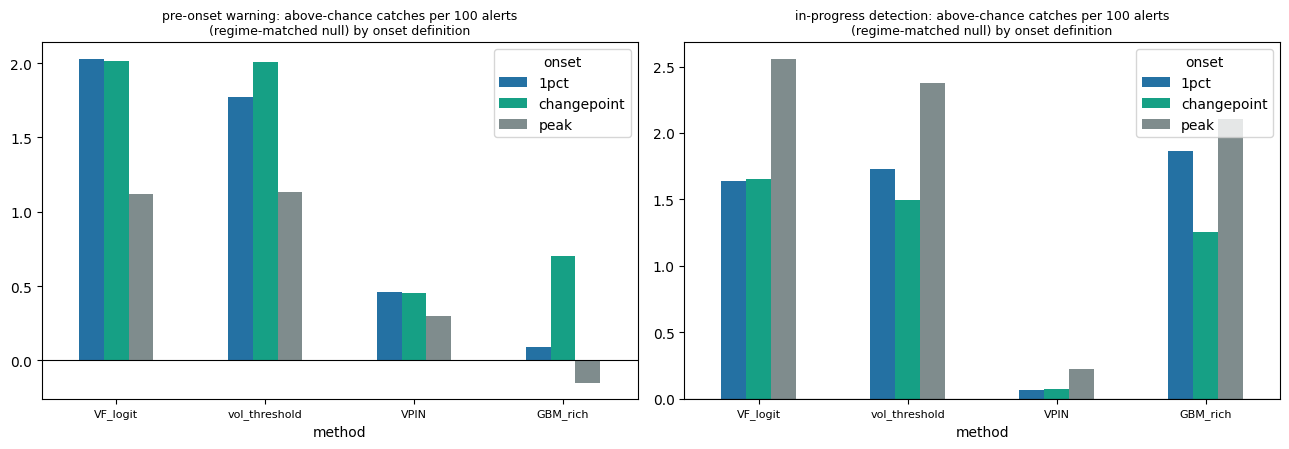

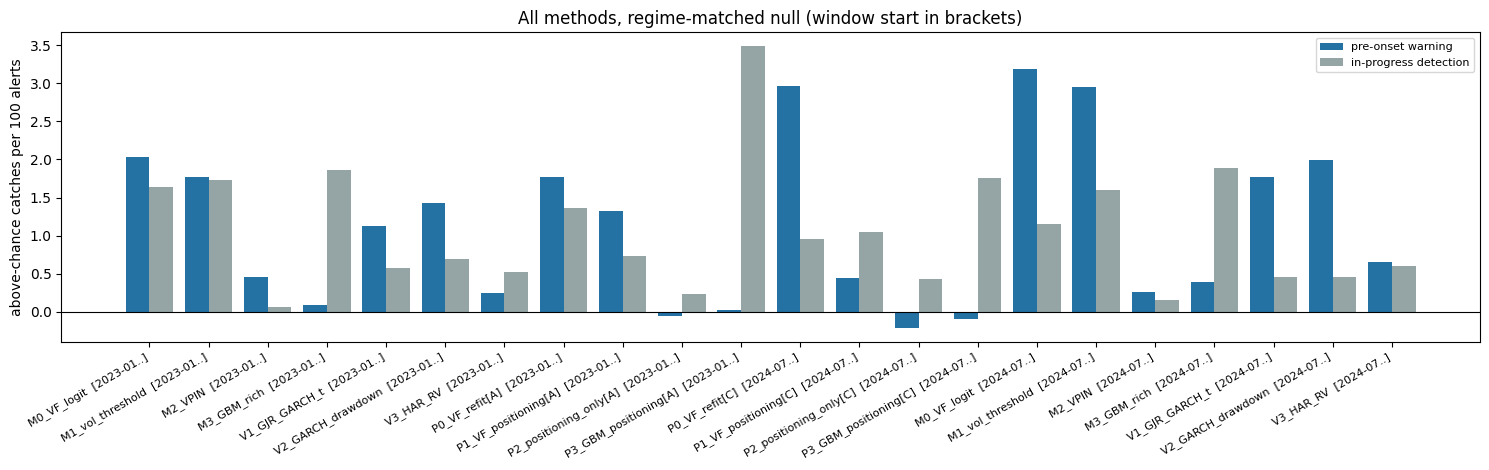

2023-01.. M0_VF_logit            alerts  800 | pre  22 (null   5.8, p 0.001) | post  17 (null   3.9, p 0.001) | per 100 alerts: pre +2.03, post +1.64
2023-01.. M1_vol_threshold       alerts  800 | pre  20 (null   5.8, p 0.001) | post  18 (null   4.2, p 0.001) | per 100 alerts: pre +1.77, post +1.73
2023-01.. M2_VPIN                alerts  800 | pre   9 (null   5.3, p 0.081) | post   4 (null   3.5, p 0.481) | per 100 alerts: pre +0.46, post +0.06
2023-01.. M3_GBM_rich            alerts  768 | pre   7 (null   6.3, p 0.435) | post  19 (null   4.7, p 0.001) | per 100 alerts: pre +0.09, post +1.86
2023-01.. V1_GJR_GARCH_t         alerts  788 | pre  15 (null   6.1, p 0.001) | post   9 (null   4.5, p 0.028) | per 100 alerts: pre +1.13, post +0.57
2023-01.. V2_GARCH_drawdown      alerts  792 | pre  18 (null   6.7, p 0.002) | post  10 (null   4.5, p 0.019) | per 100 alerts: pre +1.43, post +0.70
2023-01.. V3_HAR_RV              alerts  791 | pre   8 (null   6.1, p 0.249) | post   8 (null   3.9,

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
g = OA[OA.null == 'regime-matched']
for k, (ep, ttl) in enumerate([('pre', 'pre-onset warning'), ('post', 'in-progress detection')]):
    piv = g.pivot(index='method', columns='onset', values=f'{ep}_excess_per_100_alerts').reindex(BASE_METHODS)[['1pct', 'changepoint', 'peak']]
    piv.plot.bar(ax=axes[k], rot=0, color=['#2471a3', '#16a085', '#7f8c8d'])
    axes[k].axhline(0, color='k', lw=0.8); axes[k].set_title(f'{ttl}: above-chance catches per 100 alerts\n(regime-matched null) by onset definition', fontsize=9)
    axes[k].set_xticklabels([m.split('_', 1)[1] for m in BASE_METHODS], fontsize=8)
plt.tight_layout(); plt.savefig(OUT / '1_onset_definitions.png', dpi=140); plt.show()

fig, ax = plt.subplots(figsize=(15, 4.8))
g = NA[NA.null == 'regime-matched'].assign(label=lambda d: d.method + '  [' + d.window.str.slice(0, 7) + '..]').set_index('label')
x = np.arange(len(g)); ax.bar(x - 0.2, g.pre_excess_per_100_alerts, 0.4, color='#2471a3', label='pre-onset warning')
ax.bar(x + 0.2, g.post_excess_per_100_alerts, 0.4, color='#95a5a6', label='in-progress detection')
ax.axhline(0, color='k', lw=0.8); ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=30, ha='right', fontsize=8)
ax.set_ylabel('above-chance catches per 100 alerts'); ax.set_title('All methods, regime-matched null (window start in brackets)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / '3_new_models_yields.png', dpi=140); plt.show()


summary = dict(spec_sha256=SPEC_SHA, models_sha256=sha256_file(OUT / 'MODELS_21.json'), status='exploratory; dev 2023-01..2026-04 only',
               positioning_runs=FROZEN21['runs'], changepoint_fallbacks=int(CP_FALLBACK),
               onset_definitions=ONSET_DESC.to_dict('records'),
               onset_alerts_regime=OA[OA.null == 'regime-matched'][['method', 'onset', 'pre', 'post', 'pre_null_mean', 'post_null_mean', 'p_pre', 'p_post',
                                                                    'pre_excess_per_100_alerts', 'post_excess_per_100_alerts']].to_dict('records'),
               onset_per_minute=OP[['onset', 'score', 'auc_pre', 'in_share_of_excess', 'in_share_of_excess_lo', 'in_share_of_excess_hi',
                                    'auc_pre_within_regime']].to_dict('records'),
               positioning_univariate=UP[['feature', 'auc_pre', 'auc_pre_within_regime']].to_dict('records'),
               new_models_alerts=NA[['method', 'window', 'null', 'alerts', 'caught', 'pre', 'post', 'pre_null_mean', 'post_null_mean', 'p_pre', 'p_post',
                                     'pre_excess_per_100_alerts', 'post_excess_per_100_alerts']].to_dict('records'),
               new_models_per_minute=MA[['mask', 'score', 'auc_standard', 'auc_pre', 'auc_in', 'in_share_of_excess', 'auc_pre_within_regime']].to_dict('records'),
               p1_coefficients={n: m['coef_standardized'] for n, m in FROZEN21['models'].items() if n.startswith('P1_')}, volatility=FROZEN21['volatility'])
(OUT / 'REVIEWER_CHECKS_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
for r in summary['new_models_alerts']:
    if r['null'] == 'regime-matched':
        print(f"{r['window'][:7]}.. {r['method']:22s} alerts {r['alerts']:4d} | pre {r['pre']:3d} (null {r['pre_null_mean']:5.1f}, p {r['p_pre']:.3f}) "
              f"| post {r['post']:3d} (null {r['post_null_mean']:5.1f}, p {r['p_post']:.3f}) "
              f"| per 100 alerts: pre {r['pre_excess_per_100_alerts']:+.2f}, post {r['post_excess_per_100_alerts']:+.2f}")

## Interpretation
- A. If in-progress detection exceeds pre-onset warning under the peak and changepoint definitions too, the 1% choice does not drive the conclusion. The peak definition is the strictest (an alert must precede the peak to count as pre-onset); the changepoint definition lets the data determine the onset.
- B-1. A single positioning feature whose within-regime pre-onset AUC departs clearly from 0.5 carries information absent from the one-minute bars.
- B-2. A larger pre-onset excess for P1 (M0 + positioning) than for P0 (M0 only, same procedure) means positioning data help early warning. I train and calibrate both on the same periods, so the difference comes from the features alone.
- C. GARCH and HAR scores close to M1 (volatility threshold) in pre-onset warning mean that refined volatility models also capture only the regime. I design V2 to score high after a decline begins, so its in-progress detection is large by construction.